# compare_g6s — G6sulfur vs G6-1.5K-SAI multi-model temperature maps

Python port of `compare_g6s.m`. Compares the GeoMIP G6sulfur−SSP2-4.5
multi-model mean (7 models incl. SOCOL, 2° grid) with the G6-1.5K-SAI−Baseline
multi-model mean (3 models), and maps their difference.

`map_plots_GeoMIP.mat` is external (parent) → `.mat`. `map_plots_GeoMIP_SOCOL`
and `G615kSAI` are *created in this folder* → read from `data_py/*.npz`.

In [1]:
import sys, os
import os as _os
_r = _os.getcwd()
while not _os.path.isdir(_os.path.join(_r, "python")) and _os.path.dirname(_r) != _r:
    _r = _os.path.dirname(_r)
_os.chdir(_r)   # notebooks live in j_notebooks/; anchor to project root
sys.path.insert(0, "python")
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import mat_utils as mu
from mat_utils import brewermap, interp2, worldmap, pcolorm, geoshow_coastlines

m = mu.loadmat("../GeoMIP_G6Sulfur/map_plots_GeoMIP.mat")
LATm, LONm, x_map = m["LAT"], m["LON"], m["x_map_20"]
S = mu.load_npz("map_plots_GeoMIP_SOCOL")
lat_SOCOL = S["lat_SOCOL"].ravel(); lon_SOCOL = S["lon_SOCOL"].ravel()
x_map_S = S["x_map_20_SOCOL"]

LAT = [LATm[0, i].ravel() for i in range(6)] + [lat_SOCOL]
LON = [LONm[0, i].ravel() for i in range(6)] + [lon_SOCOL]
x_map_20 = np.empty((4, 7), dtype=object)
x_map_20[:, :6] = x_map
for im in range(4):
    x_map_20[im, 6] = np.asarray(x_map_S[0, im])

lat_int1 = np.arange(-90, 91, 2.0)
lon_int1 = np.arange(0, 361, 2.0)
nlat, nlon = lat_int1.size, lon_int1.size


def regrid(lat, lon, delta):
    lon_ext = np.append(lon, 360.0)
    d = np.vstack([delta, delta[0:1, :]])
    return interp2(lon_ext, lat, d.T, lon_int1, lat_int1, "linear", np.nan)

## GeoMIP G6sulfur − SSP2-4.5 multi-model mean (7 models)

In [2]:
sulf_int = np.full((nlat, nlon, 7), np.nan)
for im in range(7):
    sulf_int[:, :, im] = regrid(LAT[im], LON[im], x_map_20[0, im] - x_map_20[3, im])
sulf_delta_all1 = np.nanmean(sulf_int, axis=2)

## G6-1.5K-SAI − Baseline multi-model mean (3 models, from G615kSAI.npz)

In [3]:
G = mu.load_npz("G615kSAI")
LAT3, LON3 = G["LAT"], G["LON"]
ta_g6, ta_ba = G["ta_g6"], G["ta_ba"]
sulf15_int = np.full((nlat, nlon, 3), np.nan)
for im in range(3):
    lat = np.asarray(LAT3[0, im], float).ravel()
    lon = np.asarray(LON3[0, im], float).ravel()
    sulf15_int[:, :, im] = regrid(lat, lon, np.asarray(ta_g6[0, im]) - np.asarray(ta_ba[0, im]))
sulf_delta_15k = np.nanmean(sulf15_int, axis=2)

## Maps: G6sulfur, G6-1.5K-SAI, and their difference

/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


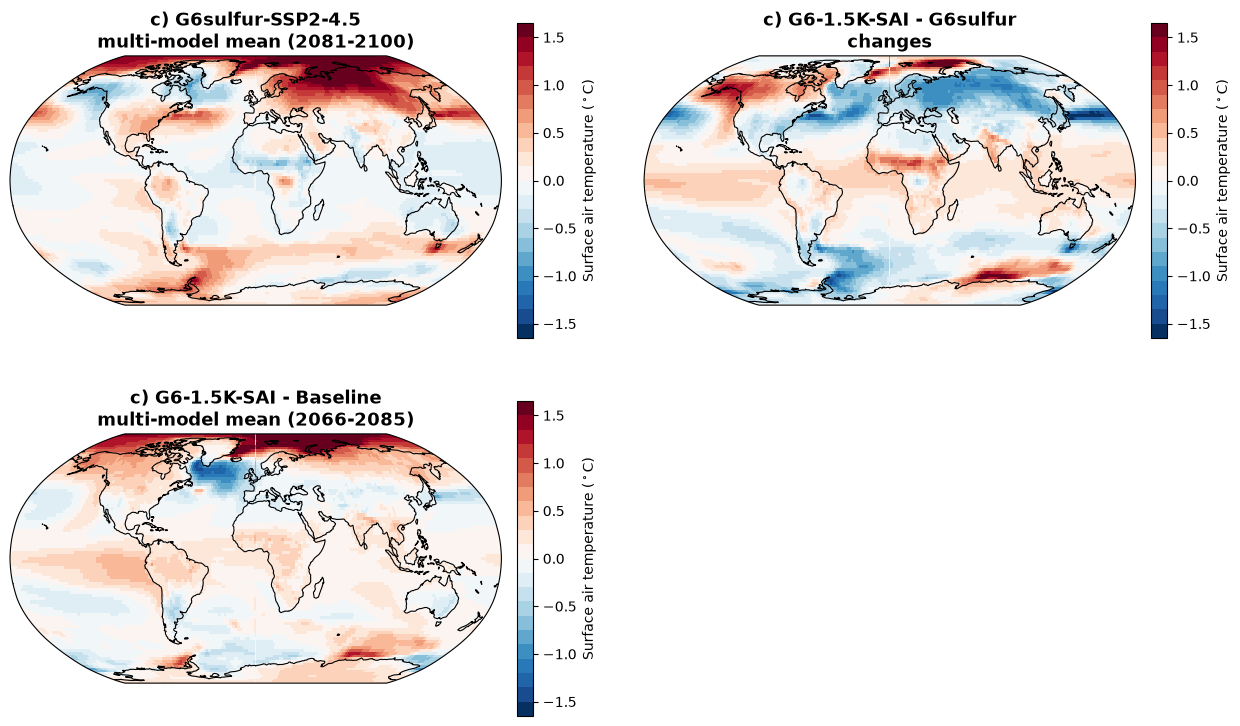

/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


saved py_outputs/maps_mean_diff.png


In [4]:
fc = brewermap(22, "*RdBu"); mmin, mmax = -1.65, 1.65
fig, axes = plt.subplots(2, 2, figsize=(15, 9),
                         subplot_kw={"projection": ccrs.Robinson()})
panels = [(axes[0, 0], sulf_delta_all1, "c) G6sulfur-SSP2-4.5\nmulti-model mean (2081-2100)"),
          (axes[1, 0], sulf_delta_15k, "c) G6-1.5K-SAI - Baseline\nmulti-model mean (2066-2085)"),
          (axes[0, 1], sulf_delta_15k - sulf_delta_all1, "c) G6-1.5K-SAI - G6sulfur\nchanges")]
for ax, Z, ttl in panels:
    mu.worldmap(ax=ax)
    mp = pcolorm(ax, lat_int1, lon_int1, Z, cmap=fc, vmin=mmin, vmax=mmax)
    geoshow_coastlines(ax)
    ax.set_title(ttl, fontsize=13, fontweight="bold")
    fig.colorbar(mp, ax=ax, orientation="vertical", fraction=0.04, pad=0.03,
                 label=r"Surface air temperature ($^\circ$C)")
axes[1, 1].axis("off")
plt.show()
os.makedirs("py_outputs", exist_ok=True)
fig.savefig("py_outputs/maps_mean_diff.png", dpi=300, bbox_inches="tight")
print("saved py_outputs/maps_mean_diff.png")